# M87 SED

In [1]:
import numpy as np
import glob as glob
import matplotlib.pyplot as plt
import matplotlib
import sys

sys.path.append('/home/emgutierrez/Dropbox/edu_luc_collab/2020_jetjet_collision/astrograv_py/modules/')
from constants_cgs import *

In [2]:
Observatories = glob.glob('obs_data/*.dat')

In [3]:
Observ_list = {}
for Obs in Observatories:
    a = np.loadtxt(Obs, skiprows=1).transpose()
    Observ_list[Obs[9:-4]] = np.array(a)

lumRIAF = np.loadtxt('./code/RIAF_radproc/build/src/adaf/lumThermal.dat').transpose()
lumRIAFsy = np.loadtxt('./code/RIAF_radproc/build/src/adaf/lumSy.dat', skiprows=1).transpose()

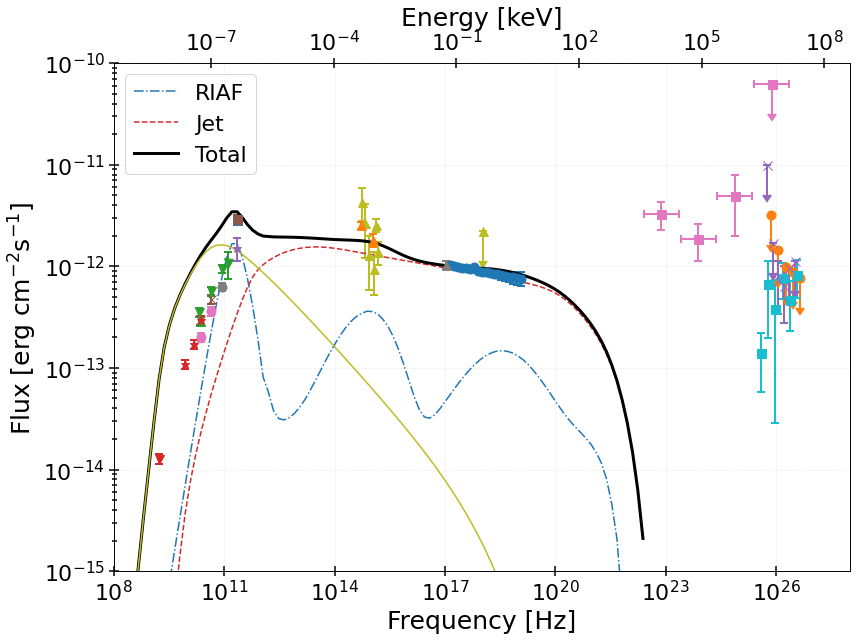

In [4]:
distance = 16.8e6 * parsec
factor = np.power(4.0*np.pi*np.square(distance), -1)
fluxSy2 = lumRIAF[2] * factor
fluxBr2 = lumRIAF[3] * factor
fluxIC2 = lumRIAF[4] * factor
fluxSSD = lumRIAF[6] * factor
fluxTot2 = lumRIAF[8] * factor
freqSy = np.power(10, lumRIAFsy[0]) * eV / planck
fluxSy = np.power(10, lumRIAFsy[1]) * factor

lumJet = np.loadtxt('./code/RIAF_radproc/build/src/adaf/lumJet.txt').transpose()
fluxJet = lumJet[1] * factor

fig, ax = plt.subplots(figsize=(12,9))

i = 0
markers = ['s', 'o', '^', 'v', '*', 'x', 's', 'o', '^']*2
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim([1e8, 1e28])
ax.set_ylim([1e-15, 1e-10])
ax.set_xlabel(r'Frequency [Hz]', fontsize=25)
ax.set_ylabel(r'Flux [erg cm$^{-2}$s$^{-1}$]', fontsize=25)
ax.tick_params(axis='both', which='major', direction='inout', labelsize=22, length=10, width=1.5)
ax.tick_params(axis='both', which='minor', direction='inout', labelsize=22, length=5, width=1.5)

ax2 = ax.twiny()
ax2.set_xlabel(r'Energy [keV]', fontsize=25)
energies_keV = ax.get_xticks()[1:-2] * planck / eV / 1e3
ax2.set_xlim([energies_keV[0], energies_keV[-1]])
ax2.set_xticks(energies_keV)
ax2.tick_params(axis='x', which='major', direction='inout', labelsize=22, length=10, width=1.5,)
ax2.tick_params(axis='x', which='minor', direction='inout', labelsize=22, length=5, width=1.5)
ax2.set_xscale('log')

for Obs_name in Observ_list.keys():
    data = Observ_list[Obs_name]
    err = np.where(data[2] > 0., data[2], 0.5*data[1])
    uplims = np.where(data[2] < 0., 1, 0)
    if Obs_name == 'Fermi':
        xerr_lo = data[0]/1.5
        xerr_hi = data[0]*2
        ax.errorbar(data[0], data[1], xerr=[xerr_lo, xerr_hi], yerr=err, ls='', marker=markers[i], markersize=9,
                uplims=uplims, elinewidth=2, capsize=4, capthick=2)
    else:
        ax.errorbar(data[0], data[1], err, ls='', marker=markers[i], markersize=9,
                uplims=uplims, elinewidth=2, capsize=4, capthick=2)
    i +=1

#ax.plot(lumRIAF[0], fluxSy)
#ax.plot(lumRIAF[0], fluxBr)
#ax.plot(lumRIAF[0], fluxIC)
ax.plot(lumRIAF[0], fluxTot2, ls='-.', color='tab:blue', label='RIAF')
ax.plot(lumJet[0], fluxJet, ls='--', color='tab:red', label='Jet')
ax.plot(lumJet[0], fluxJet + fluxTot2 + fluxSy, lw=3, color='k', label='Total')
ax.plot(freqSy, fluxSy)

plt.minorticks_on()
ax.grid(ls='--', alpha=0.2)
ax.legend(fontsize=22)
plt.tight_layout()

fig.savefig('SED.pdf')

In [10]:
Mdot_Msun_yr = 20e-4
Mbh_Msun = 6.5e9
schwRadius = 2 *gravConstant * Mbh_Msun * solarMass / cLight2
MdotEdd = 1.39e18 * Mbh_Msun
Mdot_MdotEdd = Mdot_Msun_yr * solarMass / (365.25*24*3600) / MdotEdd
print("inner acc rate = ", Mdot_MdotEdd)

Mdot_Bondi_Msun_yr = 0.2
Mdot_Bondi_MdotEdd = Mdot_Bondi_Msun_yr * solarMass / (365.25*24*3600) / MdotEdd

print("Bondi acc rate = ", Mdot_Bondi_MdotEdd)

rBondi = 0.22e3 * parsec / schwRadius
print("rBondi = ", rBondi)
sWind = np.log(Mdot_MdotEdd/Mdot_Bondi_MdotEdd) / np.log(1.0/rBondi)
print("sWind = ", sWind)

Mdot_r1e4 = Mdot_Bondi_MdotEdd * np.power(1e4/rBondi, sWind)
print("Mdot_r1e4 = ", Mdot_r1e4)

inner acc rate =  1.3947738039393865e-05
Bondi acc rate =  0.0013947738039393866
rBondi =  353638.5861392916
sWind =  0.36045390655483606
Mdot_r1e4 =  0.0003857619676711049


In [6]:
sWind = 0.3
MdotOut = Mdot_MdotEdd / np.power(1e-4, sWind)
MdotOut

0.0016579256301649688